# 2. Agents and experiments

This tutorial writes a trading agent, adds it to a market, and uses it in a
controlled experiment: does the information that a fully transparent
exchange reveals make the agent more profitable? It then shows how to
compare whole setups over many seeds and how to apply an exogenous shock.

**Setup**: `pip install -e ".[analysis]"`. Runtime: about two minutes.

Contents:
1. Anatomy of an agent
2. A contrarian that reads the crowd
3. A paired experiment: ANONYMOUS vs FULL
4. Why paired seeds matter
5. Comparing setups from the library
6. Interventions: an exogenous crash

In [1]:
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from glass_sim import Agent, AgentSpec, LimitOrder, PerpetualMarket, Side, TimeInForce, Transparency, parse_duration, scenarios

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (11, 3.5)

## 1. Anatomy of an agent

An agent is a subclass of `Agent` with an `on_wakeup(view, rng)` method. The
market wakes it on its own random (Poisson) clock, every `wake_interval`
seconds on average; the agent looks at its `MarketView` and returns a list of
actions: `MarketOrder`, `LimitOrder` (GTC, IOC or post-only, optionally
reduce-only), `Cancel` or `CancelAll`. Orders reach the exchange after a
small random latency.

Rules that keep experiments clean:
- use the `rng` argument for any randomness (never `random` or `np.random`),
  so every agent has its own reproducible stream;
- only use what `view` exposes: the view enforces the transparency level.

Other optional hooks: `on_start`, `on_fill`, `on_news`, `on_signal`,
`on_liquidation` and `next_wakeup_delay` (see the user guide).

## 2. A contrarian that reads the crowd

Retail traders in GLASS chase trends with high leverage. `CrowdFader` bets
against them. How it measures the crowd depends on what it can see:

- under **FULL** transparency every position, equity and leverage is public
  (but not names: other accounts appear under hashed ids, as on a real
  transparent exchange), so it adds up what the small, highly leveraged
  accounts actually hold: that is the retail crowd, recognised by behaviour;
- otherwise it falls back on a proxy: the net aggressive (taker) flow of the
  last two minutes, which anyone can compute from the anonymous trade tape.

In [2]:
class CrowdFader(Agent):
    """Holds a position against the crowd: small leveraged accounts' positions if visible, else recent taker flow."""

    agent_type = "crowd_fader"
    default_prefix = "fader"

    def __init__(self, wake_interval=20.0, leverage=3.0, position_threshold=2000, flow_threshold=2000):
        super().__init__(wake_interval=wake_interval)
        self.leverage = leverage
        self.position_threshold = position_threshold
        self.flow_threshold = flow_threshold

    def crowd(self, view):
        """How strongly the crowd leans long (> 1) or short (< -1)."""
        if view.can_see(Transparency.FULL):
            net = sum(a.position for a in view.accounts() if a.equity < 25_000 and a.leverage >= 3)
            return net / self.position_threshold
        recent = [t for t in view.recent_trades(500) if t.time >= view.time - 120]
        flow = sum(t.quantity if t.aggressor is Side.BUY else -t.quantity for t in recent)
        return flow / self.flow_threshold

    def on_wakeup(self, view, rng):
        signal = self.crowd(view)
        capacity = view.max_position(leverage=self.leverage)
        target = -capacity if signal > 1 else capacity if signal < -1 else 0
        delta = target - view.position
        touch = view.best_ask if delta > 0 else view.best_bid
        if delta == 0 or touch is None:
            return []
        side = Side.BUY if delta > 0 else Side.SELL
        # Cross the spread with an immediate-or-cancel order, at most 5 bps through the touch.
        limit = touch * (1.0005 if side is Side.BUY else 0.9995)
        return [LimitOrder(side, min(abs(delta), 200), view.round_price(limit), tif=TimeInForce.IOC)]

`AgentSpec` adds a group of agents to any scenario. Here two faders with
100,000 each join the reference market:

In [3]:
def with_faders(config, count=2):
    return replace(config, agents=config.agents + (AgentSpec(CrowdFader, count=count, collateral=100_000.0),))


result = PerpetualMarket(with_faders(scenarios.default(seed=3, duration=parse_duration("2h")))).run()
agents = pd.DataFrame(result.agent_table()).set_index("agent_id")
agents[agents["agent_type"] == "crowd_fader"][["return_pct", "total_pnl", "fees_paid", "trade_count", "max_abs_position", "max_drawdown_pct"]]

,return_pct,total_pnl,fees_paid,trade_count,max_abs_position,max_drawdown_pct
agent_id,,,,,,
fader_02,-1.196,-1196.227,800.070,341,3119,5.094
fader_01,-1.774,-1773.511,1046.836,396,3150,5.200


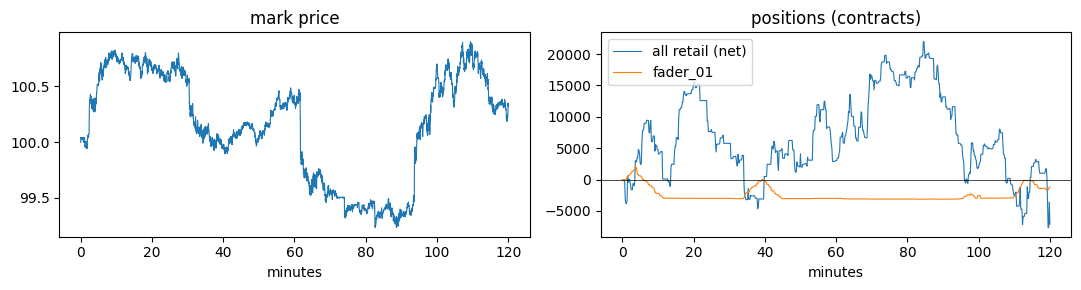

In [4]:
frames = result.to_frames()
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3))
minutes = frames["bars"].index / 60
a.plot(minutes, frames["bars"]["mark"], lw=0.8); a.set_title("mark price"); a.set_xlabel("minutes")
pos = frames["positions"]
retail = pos[[c for c in pos.columns if c.startswith("retail")]].sum(axis=1)
b.plot(pos.index / 60, retail, lw=0.8, label="all retail (net)")
b.plot(pos.index / 60, pos["fader_01"], lw=0.8, label="fader_01")
b.axhline(0, color="k", lw=0.5); b.set_title("positions (contracts)"); b.set_xlabel("minutes"); b.legend()
plt.tight_layout(); plt.show()

The agent crosses the spread every time it trades, so fees and the spread
are its main costs. Variations to try: trading less often, quoting instead
of crossing, sizing by signal strength. Here the question is whether the
information it has changes its results.

## 3. A paired experiment: ANONYMOUS vs FULL

One run proves nothing: markets are noisy. We run the same seeds under both
transparency levels. GLASS draws the exogenous world (the index path, news,
private signals) from random streams that do not depend on the agents, so a
seed gives the *same* world under both levels: the only difference is what
agents can see. Note that the scripted population also reacts to the level
(copy traders and the liquidation hunter only act under FULL).

In [5]:
SEEDS = range(1, 9)
LEVELS = (Transparency.ANONYMOUS, Transparency.FULL)
rows = []
for seed in SEEDS:
    for level in LEVELS:
        config = with_faders(scenarios.default(seed=seed, duration=parse_duration("1h"), transparency=level))
        res = PerpetualMarket(config).run()
        table = pd.DataFrame(res.agent_table())
        faders = table[table["agent_type"] == "crowd_fader"]
        summary = res.summary()
        rows.append({
            "seed": seed, "level": level.value,
            "fader_return_pct": faders["return_pct"].mean(),
            "fader_trades": faders["trade_count"].sum(),
            "spread_bps": summary["median_spread_bps"],
            "vol_1m_bps": summary["return_vol_1m_bps"],
            "liquidations": summary["liquidations"],
        })
panel = pd.DataFrame(rows)
panel.groupby("level").median(numeric_only=True).drop(columns="seed")

,fader_return_pct,fader_trades,spread_bps,vol_1m_bps,liquidations
level,,,,,
anonymous,-2.518,436.0,6.988,11.782,0.0
full,-2.377,373.5,6.989,10.921,0.0


In [6]:
wide = panel.pivot(index="seed", columns="level", values="fader_return_pct")
wide["difference"] = wide["full"] - wide["anonymous"]
print(f"FULL better on {(wide['difference'] > 0).sum()} of {len(wide)} seeds, "
      f"median paired difference {wide['difference'].median():+.3f} percentage points")
wide

FULL better on 3 of 8 seeds, median paired difference -0.684 percentage points


level,anonymous,full,difference
seed,,,
1,-2.096,-3.478,-1.382
2,-1.592,-2.057,-0.465
3,-4.172,-0.005,4.167
4,-1.592,-1.212,0.380
5,-2.949,0.276,3.225
6,-0.272,-2.696,-2.424
7,-3.571,-14.234,-10.663
8,-2.940,-3.843,-0.903


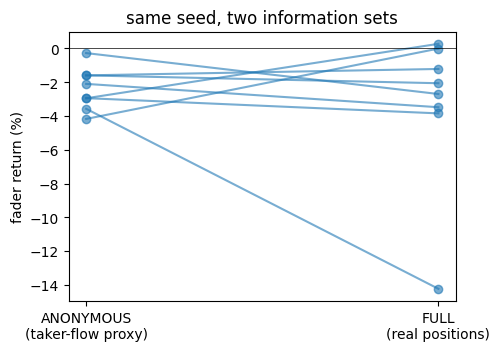

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.5))
for _seed, row in wide.iterrows():
    ax.plot([0, 1], [row["anonymous"], row["full"]], marker="o", color="tab:blue", alpha=0.6)
ax.set_xticks([0, 1], ["ANONYMOUS\n(taker-flow proxy)", "FULL\n(real positions)"])
ax.axhline(0, color="k", lw=0.5); ax.set_ylabel("fader return (%)"); ax.set_title("same seed, two information sets")
plt.show()

Each line is one seed. This is the template for a transparency experiment:
one agent design, the same worlds, and a paired comparison. For a study,
increase the number of seeds and the run length, and report the paired
differences with their spread.

## 4. Why paired seeds matter

Outcomes vary from seed to seed because the worlds differ (a calm hour, a
news-heavy hour). Taking differences on the same seed removes the part of
that variation the two treatments share:

In [8]:
def spread_of(metric):
    w = panel.pivot(index="seed", columns="level", values=metric)
    return {
        "std across seeds, ANONYMOUS": w["anonymous"].std(),
        "std across seeds, FULL": w["full"].std(),
        "std of paired differences": (w["full"] - w["anonymous"]).std(),
    }


pd.DataFrame({"1-min volatility (bps)": spread_of("vol_1m_bps"), "fader return (%)": spread_of("fader_return_pct")}).T

,"std across seeds, ANONYMOUS","std across seeds, FULL",std of paired differences
1-min volatility (bps),14.945,17.032,2.484
fader return (%),1.255,4.625,4.509


For market volatility, which is driven mostly by the shared world, the
paired differences vary several times less than the levels themselves: the
same number of runs detects a much smaller effect than independent samples
would. For the fader's return the gain is smaller, because its trades depend
on what it sees and so differ between the two treatments; outcomes driven by
the treatment itself need more seeds.

## 5. Comparing setups from the library

`compare_panels` runs two setups on the same seeds and reports medians,
paired differences and win counts for the market metrics and every
participant type. A *run spec* is a string of `key=value` pairs (`scenario`,
`seed`, `transparency`, `duration`); `glass compare` on the command line
does the same.

In [9]:
from glass_sim.compare import compare_panels

print(compare_panels("scenario=default duration=1h", "scenario=anonymous duration=1h", seeds=[1, 2, 3]))

left:  scenario=default duration=1h
right: scenario=anonymous duration=1h
seeds: 3 (1..3); paired difference = right - left on the same seed

  metric                                   median L     median R     med diff    mean diff   R > L
  trades                                      2,116        1,229         -887   -1,087.333   0/3  
  volume_contracts                          240,170      204,533      -40,750  -74,474.333   0/3  
  trades_per_minute                          35.257       20.478      -14.779      -18.117   0/3  
  mean_open_interest                     36,708.540   33,327.349   -4,575.210   -4,254.592   0/3  
  max_open_interest                          53,500       51,225       -4,095   -4,609.667   0/3  
  two_sided_book_fraction                     1.000        1.000            0            0   0/3  
  median_spread_bps                           5.977        5.978        0.001        0.001   3/3  
  mean_spread                                 0.082        0.080  

## 6. Interventions: an exogenous crash

For causal questions you can intervene in a running market.
`run_until(t)` pauses the simulation, `shock_index(log_jump)` moves the index
instantly (as a large news event would), and `run()` continues. Because the
seed fixes everything else, comparing with the unshocked run isolates the
effect of the shock.

In [10]:
config = scenarios.default(seed=4, duration=parse_duration("2h"))
baseline = PerpetualMarket(config).run()

market = PerpetualMarket(config)
market.run_until(3600.0)
market.shock_index(np.log(0.97), headline="3% crash")
shocked = market.run()

pd.DataFrame({
    "baseline": {k: baseline.summary()[k] for k in ("liquidations", "liquidated_contracts", "adl_contracts", "bad_debt", "return_vol_1m_bps")},
    "3% crash at 1h": {k: shocked.summary()[k] for k in ("liquidations", "liquidated_contracts", "adl_contracts", "bad_debt", "return_vol_1m_bps")},
})

,baseline,3% crash at 1h
liquidations,0.00,11.000
liquidated_contracts,0.00,15116.000
adl_contracts,0.00,5954.000
bad_debt,0.00,0.000
return_vol_1m_bps,13.32,46.256


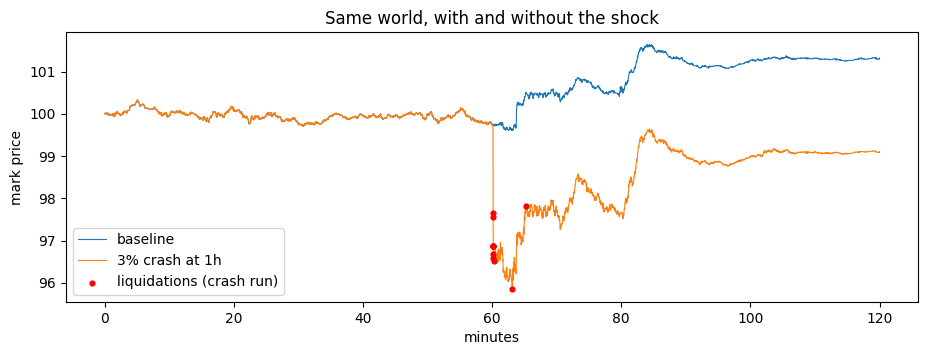

In [11]:
fig, ax = plt.subplots()
for label, res in (("baseline", baseline), ("3% crash at 1h", shocked)):
    bars = res.to_frames()["bars"]
    ax.plot(bars.index / 60, bars["mark"], lw=0.8, label=label)
liq = shocked.to_frames()["liquidations"]
ax.scatter(liq["time"] / 60, liq["mark_price"], s=12, color="red", zorder=3, label="liquidations (crash run)")
ax.set_xlabel("minutes"); ax.set_ylabel("mark price"); ax.legend(); ax.set_title("Same world, with and without the shock")
plt.show()

In [12]:
groups = pd.DataFrame({
    "baseline": {g["agent_type"]: g["return_pct"] for g in baseline.group_table()},
    "crash": {g["agent_type"]: g["return_pct"] for g in shocked.group_table()},
})
groups["effect"] = groups["crash"] - groups["baseline"]
groups.sort_values("effect")

,baseline,crash,effect
retail,-2.134,-24.068,-21.934
copy_trader,-7.466,-21.788,-14.322
informed,-0.229,-5.302,-5.074
momentum,-0.834,-5.622,-4.788
arbitrageur,0.134,-0.406,-0.540
liquidation_hunter,0.000,-0.008,-0.008
flow_follower,-1.832,0.054,1.886
market_maker,0.578,3.818,3.240
whale,-1.381,2.296,3.677


`market.execute(agent_id, actions)` similarly injects orders at the current
time, for example a large forced sale.

**Next**: [3. Reinforcement learning](03_reinforcement_learning.ipynb), where
a learning agent replaces the hand-written rules.